## **Homework 04 - Stock Markets Analytics -  Zoomcamp 2026**

## **Imports**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print(f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}")

pandas 3.0.5, scikit-learn 1.6.1


## **Data**

> **Data:** the same file as Homework 03, read from `../module-03/data/`. It is not in this repository because of its size (144 MB). To download it:
>
> ```bash
> gdown "https://drive.google.com/file/d/1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5/view?usp=sharing" -O ../module-03/data/stocks_df_combined.parquet.brotli
> ```
>
> **Environment:** the Random Forest depends on the scikit-learn version. This project pins `scikit-learn==1.6.1`, the version of the Colab run saved in the Module 4 notebook, and it reproduces the table saved in that notebook. With scikit-learn 1.9.1, the manual rules and the decision trees do not change, but Question 1 gives 1.128 and Question 2 gives 0.57.

In [2]:
DATA_PATH = "../module-03/data/stocks_df_combined.parquet.brotli"

## **Pipeline**

The homework asks for a fresh copy of the Module 4 notebook for each question. Here that notebook is reproduced as functions, and each question calls them from the start with its own setup. Tuning, Logistic Regression and the Neural Network are left out because none of them produces a simulated prediction.

In [3]:
# growth, technical patterns and dummies are listed from the dataset
TECHNICAL_INDICATORS = ['adx','adxr','apo','aroon_1','aroon_2','aroonosc','bop','cci','cmo','dx','macd','macdsignal','macdhist','macd_ext','macdsignal_ext','macdhist_ext','macd_fix','macdsignal_fix','macdhist_fix','mfi','minus_di','mom','plus_di','dm','ppo','roc','rocp','rocr','rocr100','rsi','slowk','slowd','fastk','fastd','fastk_rsi','fastd_rsi','trix','ultosc','willr','ad','adosc','obv','atr','natr','ht_dcperiod','ht_dcphase','ht_phasor_inphase','ht_phasor_quadrature','ht_sine_sine','ht_sine_leadsine','ht_trendmod','avgprice','medprice','typprice','wclprice']
CUSTOM_NUMERICAL = ["SMA10", "SMA20", "growing_moving_average", "high_minus_low_relative", "volatility", "ln_volume", "div_payout", "stock_split"]
MACRO = ["gdppot_us_yoy", "gdppot_us_qoq", "cpi_core_yoy", "cpi_core_mom", "FEDFUNDS", "DGS1", "DGS5", "DGS10"]

to_predict = "is_positive_growth_30d_future"

In [4]:
def build_dataset(drop_categorical=(), target_threshold=None):
    """
    Dataset since 2000 with dummies and the temporal split of the Module 4 notebook.

    Args:
        drop_categorical (tuple): Categorical columns left out of the dummies.
        target_threshold (float): If given, the target is 1 when growth_future_30d is above it.

    Returns:
        tuple: The DataFrame and the list of feature names.
    """
    df_full = pd.read_parquet(DATA_PATH)

    if target_threshold is not None:
        df_full[to_predict] = (df_full["growth_future_30d"] > target_threshold).astype(int)

    growth = [g for g in df_full.keys() if g.startswith("growth_") and "future" not in g]
    patterns = [g for g in df_full.keys() if "cdl" in g]

    df_full["ln_volume"] = df_full["Volume"].apply(lambda x: np.log(x + 1e-6))
    df_full["div_payout"] = (df_full["Dividends"] > 0).astype(int)
    df_full["stock_split"] = (df_full["Stock Splits"] > 0).astype(int)

    numerical = growth + TECHNICAL_INDICATORS + patterns + CUSTOM_NUMERICAL + MACRO

    df = df_full[df_full["Date"] >= "2000-01-01"].copy()
    df["Month"] = df["Month"].dt.strftime("%B")
    df["Weekday"] = df["Weekday"].astype(str)
    df["month_wom"] = df["Month"] + "_w" + ((df["Date"].dt.day - 1) // 7 + 1).astype(str)

    categorical = [c for c in ["Month", "Weekday", "Ticker", "ticker_type", "month_wom"] if c not in drop_categorical]
    dummy_variables = pd.get_dummies(df[categorical], dtype="int32")
    df = pd.concat([df, dummy_variables], axis=1).copy()

    # fixed split: 70% train, 15% validation, 15% test of the calendar days
    min_date, max_date = df["Date"].min(), df["Date"].max()
    days = (max_date - min_date).days
    train_end = min_date + pd.Timedelta(days=days * 0.7)
    val_end = train_end + pd.Timedelta(days=days * 0.15)
    df["split"] = np.where(df["Date"] <= train_end, "train", np.where(df["Date"] <= val_end, "validation", "test"))

    return df, numerical + dummy_variables.keys().to_list()

In [5]:
def add_predictions(df, features):
    """Manual rules, decision trees and Random Forest, all fitted on train + validation."""
    df["pred0_manual_cci"] = (df["cci"] > 200).astype(int)
    df["pred1_manual_prev_g1"] = (df["growth_30d"] > 1).astype(int)
    df["pred2_manual_prev_g1_and_snp"] = ((df["growth_30d"] > 1) & (df["growth_snp500_30d"] > 1)).astype(int)
    df["pred3_manual_dgs10_5"] = ((df["DGS10"] <= 4.5) & (df["DGS5"] <= 4)).astype(int)
    df["pred4_manual_dgs10_fedfunds"] = ((df["DGS10"] > 4) & (df["FEDFUNDS"] <= 4.795)).astype(int)

    X_all = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)
    is_fit = df["split"].isin(["train", "validation"]).to_numpy()
    X_train_valid, y_train_valid = X_all[is_fit], df.loc[is_fit, to_predict]

    trees = {depth: DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train_valid, y_train_valid) for depth in [10, 4, 7]}
    df["pred5_clf_10"] = trees[10].predict(X_all)
    df["pred6_clf_4"] = trees[4].predict(X_all)
    df["pred7_clf_second_best"] = trees[7].predict(X_all)

    proba_clf = trees[7].predict_proba(X_all)[:, 1]
    df["pred8_clf_second_best_rule_56"] = (proba_clf >= 0.56).astype(int)
    df["pred9_clf_second_best_rule_66"] = (proba_clf >= 0.66).astype(int)

    rf_best = RandomForestClassifier(n_estimators=100, max_depth=13, random_state=42, n_jobs=-1)
    rf_best.fit(X_train_valid, y_train_valid)

    df["proba_rf"] = rf_best.predict_proba(X_all)[:, 1]
    df["pred10_rf_best_rule_55"] = (df["proba_rf"] >= 0.55).astype(int)
    df["pred11_rf_best_rule_65"] = (df["proba_rf"] >= 0.65).astype(int)

    return df

In [6]:
def simulate(df):
    """Simulation 1 on the test set: $100 on every positive prediction, 0.2% of fees per trade."""
    df_test = df[df["split"] == "test"]
    results = []

    for pred in [k for k in df.keys() if k.startswith("pred")]:
        positive = df_test[df_test[pred] == 1]

        gross_rev = 100 * (positive["growth_future_30d"] - 1)
        fees = pd.Series(-100 * 0.002, index=positive.index)
        net_rev = (gross_rev + fees).sum()

        investments_daily = positive.groupby("Date")[pred].count()
        capital = 100 * 30 * investments_daily.quantile(0.75)

        results.append({
            "prediction": pred,
            "sim1_count_investments": len(positive),
            "sim1_gross_rev": gross_rev.sum(),
            "sim1_fees": fees.sum(),
            "sim1_net_rev": net_rev,
            "sim1_avg_investments_per_day": investments_daily.mean(),
            "sim1_capital": capital,
            "sim1_CAGR": ((capital + net_rev) / capital) ** (1 / 4),
        })

    return pd.DataFrame(results).set_index("prediction")

#### **Check: the original setup**

The notebook "as is" must be reproduced before changing anything. The table saved in it has 9861 trades and a CAGR of 1.1196 for `pred5_clf_10` (1.1195 in the homework statement), and 3111 trades and a CAGR of 1.0936 for `pred10_rf_best_rule_55`.

In [7]:
df_base, features_base = build_dataset()
df_base = add_predictions(df_base, features_base)
df_sim_base = simulate(df_base)

print(f"features: {len(features_base)}")
df_sim_base.round(4)

features: 301


,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
prediction,,,,,,,
pred0_manual_cci,921,1839.3929,-184.2,1656.1929,1.8758,6000.0,1.0628
pred1_manual_prev_g1,19158,44647.3669,-3831.6,40918.3669,18.4212,72000.0,1.1191
pred2_manual_prev_g1_and_snp,15244,33808.0942,-3048.8,30853.8942,21.7151,75000.0,1.0900
pred3_manual_dgs10_5,15910,40723.8030,-3182.0,37541.8030,31.9478,99000.0,1.0837
pred4_manual_dgs10_fedfunds,15921,18532.8800,-3184.2,15546.6800,31.9058,99000.0,1.0371
pred5_clf_10,9861,29377.3523,-1972.2,27419.1523,10.2612,48000.0,1.1196
pred6_clf_4,6677,22383.4460,-1335.4,21050.6460,30.3500,99000.0,1.0494
pred7_clf_second_best,4196,15901.0546,-839.2,15064.4546,10.8144,51000.0,1.0668
pred8_clf_second_best_rule_56,4183,15881.1520,-836.6,15047.1520,10.8088,51000.0,1.0668


## **Question 01**

- **Problem statement: Find the CAGR for the pred10_rf_best_rule_55 using the new setup (with fewer dummy variables).**

### **Solution**

`Ticker` and `month_wom` are removed from the categorical set just before the dummies are generated, which should leave 208 features instead of 301.

In [8]:
df_q1, features_q1 = build_dataset(drop_categorical=("Ticker", "month_wom"))
df_q1 = add_predictions(df_q1, features_q1)
df_sim_q1 = simulate(df_q1)

print(f"features: {len(features_q1)}")
df_sim_q1.round(4)

features: 208


,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
prediction,,,,,,,
pred0_manual_cci,921,1839.3929,-184.2,1656.1929,1.8758,6000.0,1.0628
pred1_manual_prev_g1,19158,44647.3669,-3831.6,40918.3669,18.4212,72000.0,1.1191
pred2_manual_prev_g1_and_snp,15244,33808.0942,-3048.8,30853.8942,21.7151,75000.0,1.0900
pred3_manual_dgs10_5,15910,40723.8030,-3182.0,37541.8030,31.9478,99000.0,1.0837
pred4_manual_dgs10_fedfunds,15921,18532.8800,-3184.2,15546.6800,31.9058,99000.0,1.0371
pred5_clf_10,9699,31330.7732,-1939.8,29410.3732,10.5884,51000.0,1.1206
pred6_clf_4,6677,22383.4460,-1335.4,21050.6460,30.3500,99000.0,1.0494
pred7_clf_second_best,5833,21481.0577,-1166.6,20317.0577,14.1922,87000.0,1.0539
pred8_clf_second_best_rule_56,5820,21461.1552,-1164.0,20299.7552,14.1951,87000.0,1.0538


In [9]:
pd.DataFrame({"original": df_sim_base.loc["pred10_rf_best_rule_55"], "fewer dummies": df_sim_q1.loc["pred10_rf_best_rule_55"]}).round(4)

,original,fewer dummies
sim1_count_investments,3111.0000,3514.0000
sim1_gross_rev,12236.8632,12664.9059
sim1_fees,-622.2000,-702.8000
sim1_net_rev,11622.2632,11971.5059
sim1_avg_investments_per_day,6.5772,5.1601
sim1_capital,27000.0000,18000.0000
sim1_CAGR,1.0936,1.1359


> **Answer:** the CAGR of `pred10_rf_best_rule_55` in the new setup is **1.136** (1.1359), above the 1.1195 quoted in the statement for the best original predictor.
>
> Most of the gain comes from the capital: the net revenue moves from \$11,622 to \$11,972, while the required capital falls from \$27,000 to \$18,000.

## **Question 02**

- **Problem statement: What is the probability threshold for the second-best Random Forest decision rule, if you want to have the number of average trades per day BELOW 5?**

### **Solution**

#### **`tpr_fpr_dataframe` for the Random Forest**

The model is the same as in Question 1, with the shortened dummies, so only the decision rules change.

**Note on the Module 4 notebook:** it scales `X_test` for the Logistic Regression and then passes it to `predict_proba` of tree models fitted without scaling, so its probabilities on `X_test` and its `df_scores` are not valid. `X_all` is not scaled, so the prediction columns and the simulations are not affected. Here the scores use the probabilities of the test rows, without scaling.

In [10]:
def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    scores = []

    if only_even == False:
        thresholds = np.linspace(0, 1, 101)  # [0, 0.01, 0.02, ...0.99, 1.0]
    else:
        thresholds = np.linspace(0, 1, 51)  # [0, 0.02, 0.04, ...0.98, 1.0]

    for t in thresholds:
        actual_positive = (y_true == 1)
        actual_negative = (y_true == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        if tp + fp > 0:
            precision = tp / (tp + fp)

        if tp + fn > 0:
            recall = tp / (tp + fn)

        if precision + recall > 0:
            f1_score = 2 * precision * recall / (precision + recall)

        accuracy = (tp + tn) / (tp + tn + fp + fn)

        scores.append((t, tp, fp, fn, tn, precision, recall, accuracy, f1_score))

    columns = ["threshold", "tp", "fp", "fn", "tn", "precision", "recall", "accuracy", "f1_score"]
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores["tpr"] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores["fpr"] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [11]:
df_q1_test = df_q1[df_q1["split"] == "test"]

df_scores = tpr_fpr_dataframe(df_q1_test[to_predict].to_numpy(), df_q1_test["proba_rf"].to_numpy())
df_scores["total_trades"] = df_scores.tp + df_scores.fp

df_scores[(df_scores.threshold >= 0.55) & (df_scores.threshold <= 0.65)].round(4)

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr,total_trades
55,0.55,2168,1346,16738,12911,0.6170,0.1147,0.4547,0.1934,0.1147,0.0944,3514
56,0.56,1607,1034,17299,13223,0.6085,0.0850,0.4472,0.1492,0.0850,0.0725,2641
57,0.57,1146,743,17760,13514,0.6067,0.0606,0.4421,0.1102,0.0606,0.0521,1889
58,0.58,805,525,18101,13732,0.6053,0.0426,0.4383,0.0796,0.0426,0.0368,1330
59,0.59,538,361,18368,13896,0.5984,0.0285,0.4352,0.0543,0.0285,0.0253,899
60,0.60,350,233,18556,14024,0.6003,0.0185,0.4334,0.0359,0.0185,0.0163,583
61,0.61,220,132,18686,14125,0.6250,0.0116,0.4326,0.0228,0.0116,0.0093,352
62,0.62,133,71,18773,14186,0.6520,0.0070,0.4318,0.0139,0.0070,0.0050,204
63,0.63,74,49,18832,14208,0.6016,0.0039,0.4307,0.0078,0.0039,0.0034,123
64,0.64,39,26,18867,14231,0.6000,0.0021,0.4303,0.0041,0.0021,0.0018,65


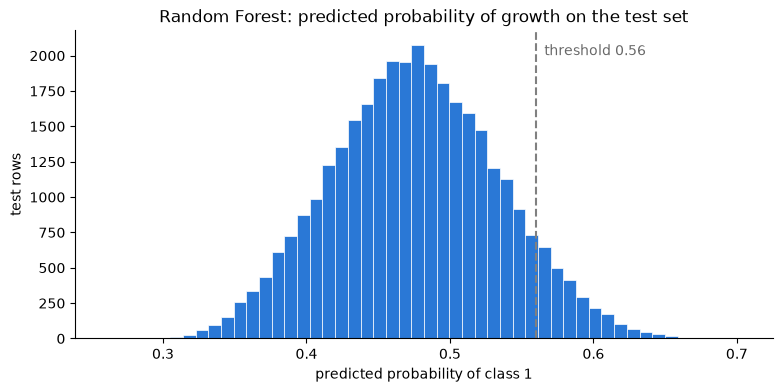

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(df_q1_test["proba_rf"], bins=50, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.axvline(0.56, linestyle="--", color="gray")
ax.annotate("threshold 0.56", xy=(0.56, 0.92), xycoords=("data", "axes fraction"), xytext=(6, 0), textcoords="offset points", color="dimgray")

ax.set_title("Random Forest: predicted probability of growth on the test set")
ax.set_xlabel("predicted probability of class 1")
ax.set_ylabel("test rows")
ax.spines[["top", "right"]].set_visible(False)

#### **Decision rules from 0.56 to 0.64**

In [13]:
df_q2 = df_q1.copy()

for i, threshold in enumerate(range(56, 65)):
    df_q2[f"pred{12 + i}_rf_best_rule_{threshold}"] = (df_q2["proba_rf"] >= threshold / 100).astype(int)

df_sim_q2 = simulate(df_q2)

df_rf_rules = df_sim_q2[df_sim_q2.index.str.contains("rf_best")].copy()
df_rf_rules["threshold"] = df_rf_rules.index.str[-2:].astype(int) / 100
df_rf_rules = df_rf_rules.sort_values("threshold")

df_rf_rules[["threshold", "sim1_count_investments", "sim1_net_rev", "sim1_avg_investments_per_day", "sim1_capital", "sim1_CAGR"]].round(4)

,threshold,sim1_count_investments,sim1_net_rev,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
prediction,,,,,,
pred10_rf_best_rule_55,0.55,3514,11971.5059,5.1601,18000.0,1.1359
pred12_rf_best_rule_56,0.56,2641,8417.1603,4.4017,15000.0,1.1178
pred13_rf_best_rule_57,0.57,1889,6272.3679,3.8085,15000.0,1.0913
pred14_rf_best_rule_58,0.58,1330,4405.7488,3.4635,15000.0,1.0665
pred15_rf_best_rule_59,0.59,899,3227.1111,3.0788,12000.0,1.0614
pred16_rf_best_rule_60,0.60,583,2267.3677,2.7762,12000.0,1.0442
pred17_rf_best_rule_61,0.61,352,1667.3959,2.5143,9750.0,1.0403
pred18_rf_best_rule_62,0.62,204,967.3820,2.0816,9000.0,1.0259
pred19_rf_best_rule_63,0.63,123,477.8563,1.6849,6000.0,1.0193


In [14]:
below_5 = df_rf_rules[df_rf_rules["sim1_avg_investments_per_day"] < 5]

second_best = below_5["sim1_CAGR"].idxmax()
df_rf_rules.loc[[second_best], ["threshold", "sim1_avg_investments_per_day", "sim1_CAGR"]].round(4)

,threshold,sim1_avg_investments_per_day,sim1_CAGR
prediction,,,
pred12_rf_best_rule_56,0.56,4.4017,1.1178


> **Answer:** the threshold is **0.56** (`pred12_rf_best_rule_56`), with 4.4 trades per day on average and a CAGR of 1.118. It is the best rule below 5 trades per day; `pred10_rf_best_rule_55` keeps the highest CAGR (1.136), with 5.2 trades per day.

## **Question 03**

- **Problem statement: What is the number of trades for the best predictor pred5_clf_10 (after redefining the target variable)?**

### **Solution**

A fresh copy of the original setup, with all the dummies. The target becomes 1 when `growth_future_30d > 1.022`, and 0 otherwise.

In [15]:
df_q3, features_q3 = build_dataset(target_threshold=1.022)

print(f"share of class 1: {df_q3[to_predict].mean():.3f}")
df_q3["growth_future_30d"].describe().round(4)

share of class 1: 0.491


count    201302.0000
mean          1.0234
std           0.1156
min           0.2461
25%           0.9612
50%           1.0206
75%           1.0822
max           5.1797
Name: growth_future_30d, dtype: float64

In [16]:
df_q3 = add_predictions(df_q3, features_q3)
df_sim_q3 = simulate(df_q3)

df_sim_q3.sort_values("sim1_CAGR", ascending=False).round(4)

,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
prediction,,,,,,,
pred5_clf_10,7337,18975.5556,-1467.4,17531.1556,8.0098,30000.0,1.1219
pred1_manual_prev_g1,19158,44647.3669,-3831.6,40918.3669,18.4212,72000.0,1.1191
pred2_manual_prev_g1_and_snp,15244,33808.0942,-3048.8,30853.8942,21.7151,75000.0,1.0900
pred7_clf_second_best,10532,24570.0087,-2106.4,22474.0087,12.6739,57000.0,1.0866
pred3_manual_dgs10_5,15910,40723.8030,-3182.0,37541.8030,31.9478,99000.0,1.0837
pred8_clf_second_best_rule_56,10276,22124.8483,-2055.2,20080.0483,12.4860,54000.0,1.0822
pred9_clf_second_best_rule_66,9746,19278.9596,-1949.2,17340.1596,13.4799,57000.0,1.0687
pred0_manual_cci,921,1839.3929,-184.2,1656.1929,1.8758,6000.0,1.0628
pred10_rf_best_rule_55,229,1691.8061,-45.8,1646.6061,2.2451,6000.0,1.0625


In [17]:
pd.DataFrame({"original target": df_sim_base.loc["pred5_clf_10"], "target above 1.022": df_sim_q3.loc["pred5_clf_10"]}).round(4)

,original target,target above 1.022
sim1_count_investments,9861.0000,7337.0000
sim1_gross_rev,29377.3523,18975.5556
sim1_fees,-1972.2000,-1467.4000
sim1_net_rev,27419.1523,17531.1556
sim1_avg_investments_per_day,10.2612,8.0098
sim1_capital,48000.0000,30000.0000
sim1_CAGR,1.1196,1.1219


> **Answer:** `pred5_clf_10` is still the best predictor and makes **8 trades per day** on average (8.01), down from 10.26, with a CAGR of 1.122. Over the 4 test years that is 7337 trades in total, down from 9861.
>
> The form offers values from 6 to 9, so the question is read as trades per day, the measure used in the statement of this question.

## **Question 04**

- **Problem statement: [EXPLORATORY] Briefly describe your ideal trading strategy.**

### **Solution**

> **Answer:** I would use a Random Forest retrained annually on the previous five years, including only observations whose 30-session outcomes are already known. Stocks with predicted probabilities of at least 0.55 would become buy candidates. A fixed initial budget would fund at most 20 equally sized positions, one per ticker, with purchases limited by available cash. When candidates exceed available slots, I would prioritize lower recent volatility. Positions would close after 30 trading sessions, accounting for fees of 0.1% per side. I would evaluate this strategy against a fixed model and the same portfolio rules without an ML filter.